--- Fit Results for 1.5% Copper sulphate $T_1$ Recovery ---
Calculated T1: 25.58 ± 0.33 ms
Fitted plateau (a): 1.95 ± 0.02 V
Fitted amplitude (k): 4.29 ± 0.02 V



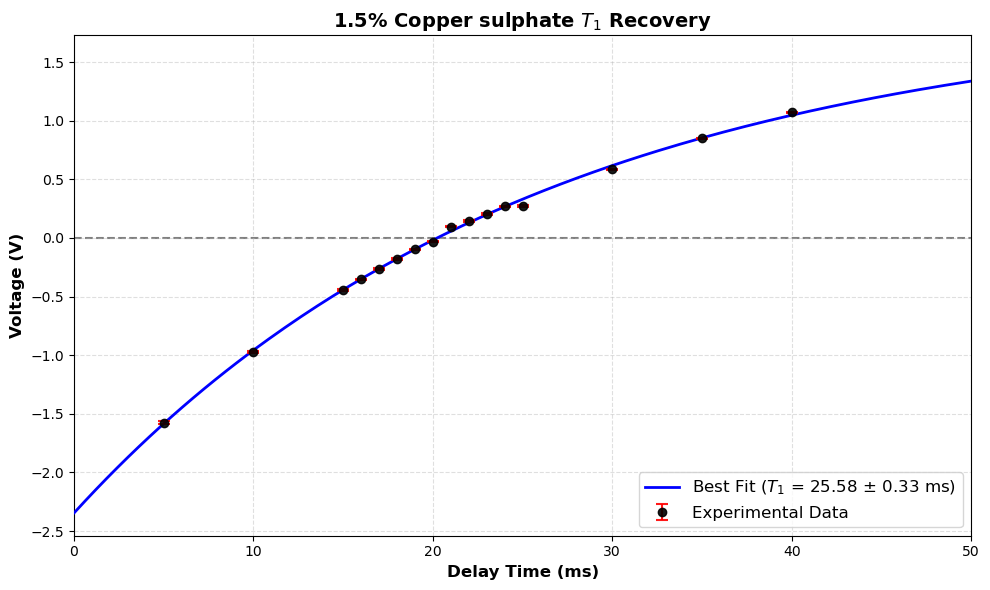

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def process_and_plot(filename, title):
    # 1. Load and Clean Data
    data = pd.read_csv(filename, encoding='windows-1252')
    data = data.iloc[:, 0:3].dropna()

    # Extract columns
    t = data.iloc[:, 0].values        
    V = data.iloc[:, 1].values   

    # Extract 3rd column (Standard Deviation) and convert mV to V
    std_dev = data.iloc[:, 2].values / 1000 
    std_dev = np.where(std_dev == 0, 1e-9, std_dev) # Prevent divide-by-zero errors

    # 2. Define the Mathematical Model
    def recovery_model(t, a, k, T1):
        return a - k * np.exp(-t / T1)

    # 3. Initial Guesses and Bounds
    p0 = [7.0, 14.0, 108.0]
    bounds = ([0, 0, 0], [20, 30, 300])

    # 4. Perform the Curve Fit
    popt, pcov = curve_fit(
        recovery_model, t, V, 
        p0=p0, 
        sigma=std_dev, 
        absolute_sigma=True,
        bounds=bounds
    )

    a_fit, k_fit, T1_fit = popt
    perr = np.sqrt(np.diag(pcov))
    a_err, k_err, T1_err = perr  

    print(f"--- Fit Results for {title} ---")
    print(f"Calculated T1: {T1_fit:.2f} ± {T1_err:.2f} ms")
    print(f"Fitted plateau (a): {a_fit:.2f} ± {a_err:.2f} V")
    print(f"Fitted amplitude (k): {k_fit:.2f} ± {k_err:.2f} V\n")

    # 5. Plotting the Graph
    plt.figure(figsize=(10, 6))

    # Plot raw data with highly visible red error bars
    plt.errorbar(t, V, yerr=std_dev, fmt='o', color='black', 
                 ecolor='red', elinewidth=1.5, capsize=4, capthick=1.5, 
                 label='Experimental Data', alpha=0.9, zorder=5)

    # Generate a smooth curve for the fitted line
    t_smooth = np.linspace(0, max(t) + 20, 200) 

    # Plot the best fit curve AND add the calculated error to the legend
    plt.plot(t_smooth, recovery_model(t_smooth, *popt), color='blue', linewidth=2, 
             label=f'Best Fit ($T_1$ = {T1_fit:.2f} $\pm$ {T1_err:.2f} ms)', zorder=3)

    # Formatting the graph
    plt.axhline(0, color='gray', linestyle='--', zorder=1)
    plt.xlim(0, max(t) + 10) 
    plt.xlabel('Delay Time (ms)', fontsize=12, fontweight='bold')
    plt.ylabel('Voltage (V)', fontsize=12, fontweight='bold')
    plt.title(title, fontsize=14, fontweight='bold')
    plt.legend(fontsize=12, loc='lower right')
    plt.grid(alpha=0.4, linestyle='--')

    # Show the plot instead of saving it
    plt.tight_layout()
    plt.show()
    # Process 100% Glycerol using the matching file path
process_and_plot(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\lowest one 1.5 %\T1 saved.csv", '1.5% Copper sulphate $T_1$ Recovery')

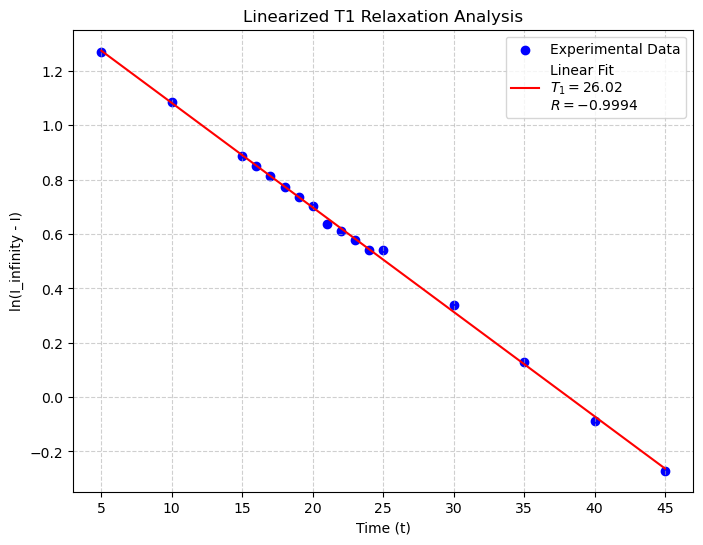

In [6]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

# 1. Load data
df = pd.read_csv(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\lowest one 1.5 %\T1 saved.csv")
time = df.iloc[:17, 6].values    # Time column
voltage = df.iloc[:17, 1].values # Voltage column

# 2. Linearize the data
# We use I_infinity = 1.99 (the plateau identified by non-linear regression)
I_inf = 1.9888
y = np.log(I_inf - voltage)
x = time

# 3. Perform Linear Regression
res = linregress(x, y)
t1_val = -1 / res.slope
r_val = res.rvalue

# 4. Plotting
plt.figure(figsize=(8, 6))
plt.scatter(x, y, color='blue', label='Experimental Data')
plt.plot(x, res.slope * x + res.intercept, 'r-', 
         label=f'Linear Fit\n$T_1 = {t1_val:.2f}$\n$R = {r_val:.4f}$')

plt.xlabel("Time (t)")
plt.ylabel("ln(I_infinity - I)")
plt.title("Linearized T1 Relaxation Analysis")
plt.legend(loc='best')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()